In [1]:
!pip install -U transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 27.3 MB/s  0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 5.20.2
    Uninstalling transformers-5.20.2:
      Successfully uninstalled transformers-5.20.2


## Local Inference on GPU 
Model page: https://huggingface.co/ProsusAI/finbert

⚠️ If the generated code snippets do not work, please open an issue on either the [model repo](https://huggingface.co/ProsusAI/finbert)
			and/or on [huggingface.js](https://github.com/huggingface/huggingface.js/blob/main/packages/tasks/src/model-libraries-snippets.ts) 🙏

In [2]:
# Use a pipeline as a high-level helper
from transformers import pipeline

pipe = pipeline("text-classification", model="ProsusAI/finbert")

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [3]:
# pip install -U transformers accelerate
# Load model directly
from transformers import AutoTokenizer, AutoModelForSequenceClassification

tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")
model = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert", device_map="auto")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [4]:
text = "The company reported strong revenue growth."

result = pipe(text, top_k=None)
print(result)

[{'label': 'positive', 'score': 0.9531024098396301}, {'label': 'neutral', 'score': 0.03277944400906563}, {'label': 'negative', 'score': 0.014118149876594543}]


In [5]:
import torch

text = "The company reported strong revenue growth."

inputs = tokenizer(text, return_tensors="pt")

device = next(model.parameters()).device
inputs = {key: value.to(device) for key, value in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

logits = outputs.logits
probabilities = torch.softmax(logits, dim=-1)

print("Logits:", logits)
print("Probabilities:", probabilities)

Logits: tensor([[ 2.1083, -2.1040, -1.2617]], device='cuda:0')
Probabilities: tensor([[0.9531, 0.0141, 0.0328]], device='cuda:0')


## Testing news text

In [6]:
test_texts = [
    "The company reported record revenue and strong earnings.",
    "The firm announced significant layoffs after disappointing results.",
    "The company maintained its earnings guidance.",
    "Shares declined following weaker-than-expected quarterly results.",
    "The company reported revenue in line with analyst expectations.",
    "Nothing new to the company.",
    "Massive downfall to the Tesla after the war striking USA.",
    "UPDATE: Citigroup Reiterates Neutral Rating, Raises PT on American Tower Corp."
]

results = pipe(test_texts, top_k=None)

for text, result in zip(test_texts, results):
    print("\nText:", text)
    print(result)


Text: The company reported record revenue and strong earnings.
[{'label': 'positive', 'score': 0.9470416307449341}, {'label': 'neutral', 'score': 0.039386894553899765}, {'label': 'negative', 'score': 0.013571476563811302}]

Text: The firm announced significant layoffs after disappointing results.
[{'label': 'negative', 'score': 0.9727678298950195}, {'label': 'neutral', 'score': 0.0194539912045002}, {'label': 'positive', 'score': 0.007778194732964039}]

Text: The company maintained its earnings guidance.
[{'label': 'positive', 'score': 0.6881186962127686}, {'label': 'neutral', 'score': 0.2923906147480011}, {'label': 'negative', 'score': 0.019490676000714302}]

Text: Shares declined following weaker-than-expected quarterly results.
[{'label': 'negative', 'score': 0.9695258140563965}, {'label': 'neutral', 'score': 0.02303312160074711}, {'label': 'positive', 'score': 0.007441041059792042}]

Text: The company reported revenue in line with analyst expectations.
[{'label': 'positive', 'score

## Remote Inference via Inference Providers 
Ensure you have a valid **HF_TOKEN** set in your environment. You can get your token from [your settings page](https://huggingface.co/settings/tokens). Note: running this may incur charges above the free tier.
The following Python example shows how to run the model remotely on HF Inference Providers, automatically selecting an available inference provider for you. 
For more information on how to use the Inference Providers, please refer to our [documentation and guides](https://huggingface.co/docs/inference-providers/en/index).

In [7]:
# import os
# os.environ['HF_TOKEN'] = 'YOUR_TOKEN_HERE'

In [8]:
# import os
# from huggingface_hub import InferenceClient

# client = InferenceClient(
#     provider="auto",
#     api_key=os.environ["HF_TOKEN"],
# )

# result = client.text_classification(
#     "I like you. I love you",
#     model="ProsusAI/finbert",
# )

In [9]:
import pandas as pd

file_path = '/kaggle/input/datasets/qkhilithi3122411100/top10-official-news-2013-2023/top10_official_news_2013_2023.csv'
# Sử dụng low_memory=False để bỏ cảnh báo DtypeWarning trước đó
df = pd.read_csv(file_path, low_memory=False)

print("Các cột hiện có:", df.columns.tolist())
df.head(2)

Các cột hiện có: ['Standard_Ticker', 'Date', 'Article_title', 'Stock_symbol', 'Url', 'Publisher', 'Author', 'Article', 'Lsa_summary', 'Luhn_summary', 'Textrank_summary', 'Lexrank_summary', 'Unnamed: 0']


,Standard_Ticker,Date,Article_title,Stock_symbol,Url,Publisher,Author,Article,Lsa_summary,Luhn_summary,Textrank_summary,Lexrank_summary,Unnamed: 0
0,AMT,2013-01-02 00:00:00 UTC,"UPDATE: Citigroup Reiterates Neutral Rating, R...",AMT,https://www.benzinga.com/analyst-ratings/analy...,Dwight Einhorn,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AMT,2013-01-02 00:00:00 UTC,Citigroup Maintains Neutral on American Tower ...,AMT,https://www.benzinga.com/news/13/01/3209128/ci...,Juan Lopez,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
import torch
from transformers import pipeline
from tqdm.auto import tqdm

# 1. Xác định thiết bị tính toán: GPU nếu có, ngược lại dùng CPU
device = 0 if torch.cuda.is_available() else -1
print(f"Đang chạy trên thiết bị: {'GPU' if device == 0 else 'CPU'}")

# 2. Khởi tạo pipeline sentiment-analysis với FinBERT
sentiment_pipe = pipeline(
    "sentiment-analysis",
    model="ProsusAI/finbert",
    tokenizer="ProsusAI/finbert",
    device=device,
    truncation=True,
    max_length=128 # Tiêu đề ngắn nên 128 token là tối ưu tốc độ
)

# 3. Thay 'headline' bằng tên cột tiêu đề thực tế trong DataFrame của bạn
text_col = 'Acticle_title' if 'Acticle_title' in df.columns else df.columns[1]

# Loại bỏ các dòng trống/NaN và ép kiểu chuỗi
texts = df[text_col].fillna("").astype(str).tolist()

# 4. Dự đoán theo batch
batch_size = 64
results = []

for out in tqdm(sentiment_pipe(texts, batch_size=batch_size), total=len(texts), desc="Đang phân tích cảm xúc"):
    results.append(out)

# 5. Lưu kết quả nhãn và điểm tin cậy vào DataFrame
df['sentiment_label'] = [res['label'] for res in results]
df['sentiment_score'] = [res['score'] for res in results]

# Lưu file kết quả ra thư mục làm việc của Kaggle
df.to_csv('/kaggle/working/news_with_sentiment.csv', index=False)
print("Đã hoàn tất và lưu file tại /kaggle/working/news_with_sentiment.csv")

Đang chạy trên thiết bị: GPU


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Đang phân tích cảm xúc:   0%|          | 0/92721 [00:00<?, ?it/s]

Đã hoàn tất và lưu file tại /kaggle/working/news_with_sentiment.csv


/tmp/ipykernel_23/419744471.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


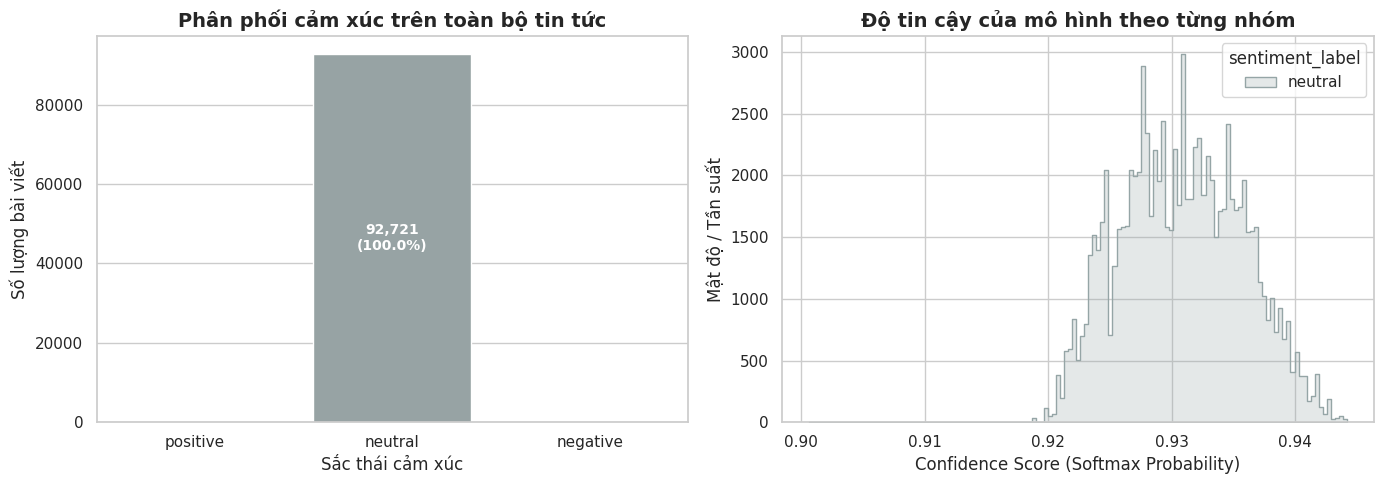

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập phong cách hiển thị
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bảng màu đại diện: Xanh lá (Positive), Đỏ (Negative), Xám (Neutral)
color_palette = {"positive": "#2ecc71", "negative": "#e74c3c", "neutral": "#95a5a6"}

# 1. Biểu đồ đếm số lượng & tỷ lệ phần trăm
sns.countplot(
    data=df, 
    x='sentiment_label', 
    order=['positive', 'neutral', 'negative'],
    palette=color_palette, 
    ax=axes[0]
)
axes[0].set_title('Phân phối cảm xúc trên toàn bộ tin tức', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Sắc thái cảm xúc', fontsize=12)
axes[0].set_ylabel('Số lượng bài viết', fontsize=12)

# Hiển thị số lượng và % trên đầu từng cột
total = len(df)
for p in axes[0].patches:
    height = p.get_height()
    pct = (height / total) * 100
    axes[0].annotate(f'{int(height):,}\n({pct:.1f}%)',
                     (p.get_x() + p.get_width() / 2., height / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=10)

# 2. Phân bố điểm số tin cậy (Confidence Score)
sns.histplot(
    data=df, 
    x='sentiment_score', 
    hue='sentiment_label', 
    palette=color_palette, 
    element='step', 
    common_norm=False, 
    ax=axes[1]
)
axes[1].set_title('Độ tin cậy của mô hình theo từng nhóm', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Confidence Score (Softmax Probability)', fontsize=12)
axes[1].set_ylabel('Mật độ / Tần suất', fontsize=12)

plt.tight_layout()
plt.show()

In [12]:
# Giả sử cột ngày tên là 'date'
if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    df['year'] = df['date'].dt.year
    
    # Tính số lượng theo từng năm và sắc thái
    yearly_sentiment = df.groupby(['year', 'sentiment_label']).size().unstack(fill_value=0)
    
    yearly_sentiment[['positive', 'neutral', 'negative']].plot(
        kind='bar', 
        stacked=True, 
        figsize=(12, 6), 
        color=['#2ecc71', '#95a5a6', '#e74c3c']
    )
    plt.title('Biến động số lượng cảm xúc tin tức theo từng năm (2013 - 2023)', fontsize=14, fontweight='bold')
    plt.xlabel('Năm', fontsize=12)
    plt.ylabel('Số lượng tin', fontsize=12)
    plt.legend(title='Cảm xúc')
    plt.show()